# Análise de terremotos (1990–2023)

Este notebook reúne **preparação dos dados (wrangling) e análise exploratória**. A ideia é que todo o caminho, desde os arquivos originais até as tabelas usadas na análise, fique visível e possa ser executado em sequência.

## O que será feito

1. Carregar e filtrar os terremotos do **USGS**.
2. Associar cada terremoto a um país usando suas coordenadas.
3. Identificar terremotos principais (*mainshocks*) e réplicas.
4. Preparar os registros de mortes da **NOAA** e relacioná-los aos eventos do USGS.
5. Preparar PIB per capita e densidade populacional do **Banco Mundial**.
6. Unificar as fontes, tratar os dados ausentes e gerar as tabelas finais.
7. Fazer algumas verificações e análises exploratórias.

> **Como executar:** rode as células de cima para baixo. Os arquivos originais devem ficar na pasta `dados/`, e os resultados serão gravados na pasta `saida/`.

> **No Google Colab:** a pasta `projeto_sismos` precisa estar no Google Drive, com as pastas `dados` e `saida` dentro dela. A próxima célula tenta localizar automaticamente `/content/drive/MyDrive/projeto_sismos`. Se o nome ou local da pasta for diferente, ajuste `PASTA_PROJETO` nela.

In [19]:
# 1. Bibliotecas e localização dos arquivos

from pathlib import Path
import warnings
import importlib.util
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# GeoPandas e Shapely são usados para associar as coordenadas aos países.
# Se não estiverem instalados, o notebook tenta instalá-los automaticamente.
if importlib.util.find_spec('geopandas') is None or importlib.util.find_spec('shapely') is None:
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q', 'geopandas', 'shapely'
    ])

import geopandas as gpd
from shapely.ops import nearest_points

# No Colab, montar o Google Drive para acessar a pasta do projeto.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    esta_no_colab = True
except ImportError:
    esta_no_colab = False

# Procurar a pasta do projeto nos locais mais comuns.
if esta_no_colab:
    opcoes_pasta = [
        Path('/content/drive/MyDrive/projeto_sismos'),
        Path('/content/projeto_sismos'),
        Path.cwd(),
    ]
else:
    opcoes_pasta = [Path.cwd(), Path.cwd() / 'projeto_sismos']

PASTA_PROJETO = next(
    (p for p in opcoes_pasta if (p / 'dados').is_dir()),
    None
)

if PASTA_PROJETO is None:
    raise FileNotFoundError(
        'Não encontrei a pasta dados/. Ajuste opcoes_pasta para apontar '
        'para a pasta projeto_sismos que contém os arquivos originais.'
    )

PASTA_DADOS = PASTA_PROJETO / 'dados'
PASTA_SAIDA = PASTA_PROJETO / 'saida'
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

print('Pasta do projeto:', PASTA_PROJETO)
print('Pasta de dados:', PASTA_DADOS)
print('Pasta de saída:', PASTA_SAIDA)

Pasta do projeto: c:\Users\pedro\OneDrive\Área de Trabalho\projeto_sismos
Pasta de dados: c:\Users\pedro\OneDrive\Área de Trabalho\projeto_sismos\dados
Pasta de saída: c:\Users\pedro\OneDrive\Área de Trabalho\projeto_sismos\saida


## 2. Parâmetros do processamento

Esta célula centraliza os critérios usados no trabalho. Assim, fica mais fácil localizar e explicar os filtros e tolerâncias.

In [20]:
# Período e filtro inicial dos terremotos
ANO_INICIAL = 1990
ANO_FINAL = 2023
MAGNITUDE_MINIMA = 5.5

# Critérios geográficos e de correspondência USGS x NOAA
DISTANCIA_MAXIMA_MAR_KM = 250
DISTANCIA_MATCH_KM = 200
DIFERENCA_MAGNITUDE_MAX = 1.0

# Critérios para identificar réplicas
DIAS_JANELA_REPLICA = 30
RAIO_MINIMO_REPLICA_KM = 100

# Banco Mundial: preencher lacunas nas pontas da série por até 12 anos
LIMITE_IMPUTACAO_ANOS = 12
JANELA_COVARIAVEIS_ANOS = 5

# Indicador por país considera eventos com magnitude a partir de 6.0
MAGNITUDE_MINIMA_PAIS = 6.0

# Caso específico: mortes do evento de Pinatubo foram atribuídas à erupção,
# e não ao terremoto. A chave usa data e código ISO3.
EVENTOS_VULCANICOS_A_EXCLUIR = [('1991-06-15', 'PHL')]

# Arquivos de entrada
ARQUIVO_USGS = PASTA_DADOS / 'usgs_1990_2023_m55.csv'
ARQUIVO_NOAA = PASTA_DADOS / 'noaa_earthquakes.tsv'
ARQUIVO_PIB = PASTA_DADOS / 'API_NY.GDP.PCAP.CD_DS2_en_csv_v2_1529.csv'
ARQUIVO_DENSIDADE = PASTA_DADOS / 'API_EN.POP.DNST_DS2_en_csv_v2_7671.csv'
ARQUIVO_METADADOS_BM = PASTA_DADOS / 'Metadata_Country_API_NY.GDP.PCAP.CD_DS2_en_csv_v2_1529.csv'
ARQUIVO_MAPA = PASTA_DADOS / 'ne_50m_admin_0_countries.zip'
ARQUIVO_COVARIAVEIS_EXTRA = PASTA_DADOS / 'covariaveis_extra.csv'

arquivos_necessarios = [
    ARQUIVO_USGS, ARQUIVO_NOAA, ARQUIVO_PIB, ARQUIVO_DENSIDADE,
    ARQUIVO_METADADOS_BM, ARQUIVO_MAPA
]
arquivos_ausentes = [str(p) for p in arquivos_necessarios if not p.exists()]
if arquivos_ausentes:
    raise FileNotFoundError('Estão faltando estes arquivos:\n' + '\n'.join(arquivos_ausentes))

print('Parâmetros carregados. Arquivos de entrada encontrados:', len(arquivos_necessarios))

Parâmetros carregados. Arquivos de entrada encontrados: 6


## 3. USGS — carregar e filtrar terremotos

O USGS fornece a data, as coordenadas, a profundidade e a magnitude dos terremotos.

Nesta etapa:
- selecionamos apenas as colunas necessárias;
- convertemos a data para o formato de data do Pandas;
- removemos registros duplicados e linhas sem informações essenciais;
- mantemos o período de 1990 a 2023 e magnitude igual ou superior a 5,5.

In [21]:
colunas_usgs = [
    'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place', 'id'
]

usgs = pd.read_csv(
    ARQUIVO_USGS,
    usecols=colunas_usgs,
    encoding_errors='replace'
)

usgs['time'] = pd.to_datetime(usgs['time'], utc=True).dt.tz_convert(None)
usgs = usgs.drop_duplicates(subset='id')
usgs = usgs.dropna(subset=['time', 'latitude', 'longitude', 'mag'])

# Aplicar o período e a magnitude mínima definidos nos parâmetros.
usgs = usgs[
    usgs['time'].dt.year.between(ANO_INICIAL, ANO_FINAL)
    & (usgs['mag'] >= MAGNITUDE_MINIMA)
].copy()

# Ordenar por data e reorganizar o índice para facilitar as próximas etapas.
usgs = usgs.sort_values('time').reset_index(drop=True)

print(f'Eventos USGS após os filtros: {len(usgs):,}')
print('Período:', usgs['time'].min(), 'até', usgs['time'].max())
print('Magnitude mínima:', usgs['mag'].min())
usgs.head()

Eventos USGS após os filtros: 16,857
Período: 1990-01-02 01:25:06.560000 até 2023-12-30 17:16:23.833000
Magnitude mínima: 5.5


,time,latitude,longitude,depth,mag,magType,id,place
0,1990-01-02 01:25:06.560,8.344,127.441,40.9,5.6,mw,usp00043u7,Philippine Islands region
1,1990-01-02 20:21:32.620,13.408,144.439,135.8,5.8,mw,usp00043v2,"23 km W of Agat Village, Guam"
2,1990-01-04 05:32:21.040,-15.397,-172.850,53.5,6.5,mw,usp00043wc,"118 km ENE of Hihifo, Tonga"
3,1990-01-05 10:10:21.810,-8.800,106.442,29.0,5.8,mw,usp00043xp,"200 km S of Pelabuhanratu, Indonesia"
4,1990-01-05 13:03:44.300,-19.258,-69.529,108.7,5.5,mw,usp00043xw,"118 km SE of Arica, Chile"


## 4. Associar cada terremoto a um país

O arquivo do USGS informa latitude e longitude, mas não traz uma coluna padronizada com o país. Para preencher essa informação, usamos o mapa do Natural Earth.

A regra é:
1. Se o ponto estiver dentro de um país, usamos esse país.
2. Se estiver no mar, procuramos o país mais próximo.
3. Só atribuímos o país quando a distância até a costa for de até 250 km. Eventos mais distantes ficam sem país e serão retirados das tabelas finais por país.

A função abaixo calcula a distância aproximada entre dois pontos da Terra (fórmula de Haversine).

In [22]:
def distancia_haversine_km(lat1, lon1, lat2, lon2):
    """Calcula a distância aproximada entre coordenadas geográficas, em km."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))

# Carregar os polígonos dos países e padronizar os códigos ISO3.
mundo = gpd.read_file(ARQUIVO_MAPA).to_crs('EPSG:4326')
iso = mundo['ISO_A3_EH'].where(
    mundo['ISO_A3_EH'].notna() & (mundo['ISO_A3_EH'] != '-99'),
    mundo['ADM0_A3']
)

# Pequenos ajustes para códigos que diferem entre as bases geográficas e o BM.
correcao_iso = {'KOS': 'XKX', 'SDS': 'SSD', 'PSX': 'PSE'}
mundo['iso3'] = iso.replace(correcao_iso)
mundo = mundo[['iso3', 'geometry']].reset_index(drop=True)

# Transformar as coordenadas dos terremotos em pontos geográficos.
pontos = gpd.GeoDataFrame(
    usgs[['latitude', 'longitude']].copy(),
    geometry=gpd.points_from_xy(usgs['longitude'], usgs['latitude']),
    crs='EPSG:4326'
)

# Primeiro, localizar os eventos que estão dentro de um país.
resultado_terra = gpd.sjoin(pontos, mundo, how='left', predicate='within')
resultado_terra = resultado_terra[~resultado_terra.index.duplicated(keep='first')]

usgs['iso3'] = resultado_terra['iso3']
usgs['dist_costa_km'] = np.where(usgs['iso3'].notna(), 0.0, np.nan)

# Para os pontos no mar, procurar o polígono de país mais próximo.
indices_no_mar = usgs.index[usgs['iso3'].isna()]
print('Eventos sem país após a busca em terra:', len(indices_no_mar))

if len(indices_no_mar) > 0:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        mais_proximo = gpd.sjoin_nearest(
            pontos.loc[indices_no_mar], mundo, how='left'
        )

    mais_proximo = mais_proximo[~mais_proximo.index.duplicated(keep='first')].copy()
    distancias = []

    for _, linha in mais_proximo.iterrows():
        poligono = mundo.geometry.iloc[int(linha['index_right'])]
        ponto_mais_proximo = nearest_points(linha.geometry, poligono)[1]
        distancia = distancia_haversine_km(
            linha.geometry.y, linha.geometry.x,
            ponto_mais_proximo.y, ponto_mais_proximo.x
        )
        distancias.append(distancia)

    mais_proximo['distancia_km'] = distancias
    dentro_limite = mais_proximo['distancia_km'] <= DISTANCIA_MAXIMA_MAR_KM

    usgs.loc[mais_proximo.index[dentro_limite], 'iso3'] = mais_proximo.loc[dentro_limite, 'iso3']
    usgs.loc[mais_proximo.index, 'dist_costa_km'] = mais_proximo['distancia_km']

print('Eventos com país atribuído:', usgs['iso3'].notna().sum())
print('Eventos ainda sem país:', usgs['iso3'].isna().sum())
usgs[['time', 'latitude', 'longitude', 'place', 'iso3', 'dist_costa_km']].head()

Eventos sem país após a busca em terra: 13540
Eventos com país atribuído: 13315
Eventos ainda sem país: 3542


,time,latitude,longitude,place,iso3,dist_costa_km
0,1990-01-02 01:25:06.560,8.344,127.441,Philippine Islands region,PHL,109.224744
1,1990-01-02 20:21:32.620,13.408,144.439,"23 km W of Agat Village, Guam",GUM,22.761546
2,1990-01-04 05:32:21.040,-15.397,-172.850,"118 km ENE of Hihifo, Tonga",WSM,181.676987
3,1990-01-05 10:10:21.810,-8.800,106.442,"200 km S of Pelabuhanratu, Indonesia",IDN,155.352420
4,1990-01-05 13:03:44.300,-19.258,-69.529,"118 km SE of Arica, Chile",CHL,0.000000


## 5. Identificar terremotos principais e réplicas

Um mesmo terremoto pode ser seguido por vários eventos menores na mesma região. Para evitar contar cada réplica como um evento independente, aplicamos uma regra de *declustering*.

O procedimento é:
1. ordenar os eventos do maior para o menor em magnitude;
2. considerar como terremoto principal (*mainshock*) o maior evento ainda não classificado;
3. procurar eventos que ocorreram nos 30 dias seguintes;
4. marcar como réplica os eventos menores que estejam dentro de um raio calculado a partir da magnitude do evento principal.

O raio nunca é menor que 100 km e pode aumentar para terremotos de maior magnitude. As linhas não são apagadas: cada evento recebe uma marcação `eh_mainshock` e, quando é réplica, o identificador do evento principal fica em `id_mainshock`.

In [23]:
# Arrays deixam o cálculo repetitivo mais rápido; cada posição representa uma linha de usgs.
tempos = usgs['time'].values
latitudes = usgs['latitude'].to_numpy()
longitudes = usgs['longitude'].to_numpy()
magnitudes = usgs['mag'].to_numpy()
ids_usgs = usgs['id'].to_numpy()

# 0 = ainda não classificado; 1 = principal; 2 = réplica.
estado = np.zeros(len(usgs), dtype=np.int8)
indice_evento_principal = np.full(len(usgs), -1)
janela_tempo = np.timedelta64(DIAS_JANELA_REPLICA, 'D')

# Processar primeiro os terremotos de maior magnitude.
ordem_magnitude = np.argsort(-magnitudes, kind='stable')

for i in ordem_magnitude:
    if estado[i] != 0:
        continue

    # Este é o maior evento ainda não classificado: será o principal.
    estado[i] = 1

    # Encontrar as linhas ocorridas entre a data do evento e os próximos 30 dias.
    inicio = np.searchsorted(tempos, tempos[i], side='left')
    fim = np.searchsorted(tempos, tempos[i] + janela_tempo, side='right')
    candidatos = np.arange(inicio, fim)
    candidatos = candidatos[estado[candidatos] == 0]

    if len(candidatos) == 0:
        continue

    # Estimar o raio de influência; garantir um mínimo de 100 km.
    raio_magnitude = 10 ** (-2.44 + 0.59 * magnitudes[i])
    raio_km = max(RAIO_MINIMO_REPLICA_KM, raio_magnitude)

    distancias = distancia_haversine_km(
        latitudes[i], longitudes[i],
        latitudes[candidatos], longitudes[candidatos]
    )

    replicas = candidatos[distancias <= raio_km]
    estado[replicas] = 2
    indice_evento_principal[replicas] = i

usgs['eh_mainshock'] = estado == 1
usgs['id_mainshock'] = [
    ids_usgs[indice] if indice >= 0 else None
    for indice in indice_evento_principal
]

print('Terremotos principais:', int((estado == 1).sum()))
print('Réplicas:', int((estado == 2).sum()))
usgs[['time', 'mag', 'place', 'eh_mainshock', 'id_mainshock']].head(10)

Terremotos principais: 12849
Réplicas: 4008


,time,mag,place,eh_mainshock,id_mainshock
0,1990-01-02 01:25:06.560,5.6,Philippine Islands region,True,NaN
1,1990-01-02 20:21:32.620,5.8,"23 km W of Agat Village, Guam",True,NaN
2,1990-01-04 05:32:21.040,6.5,"118 km ENE of Hihifo, Tonga",True,NaN
3,1990-01-05 10:10:21.810,5.8,"200 km S of Pelabuhanratu, Indonesia",True,NaN
4,1990-01-05 13:03:44.300,5.5,"118 km SE of Arica, Chile",True,NaN
5,1990-01-05 18:27:00.120,6.0,"189 km SW of La Cruz de Loreto, Mexico",True,NaN
6,1990-01-06 21:44:56.260,6.0,South Indian Ocean,True,NaN
7,1990-01-07 09:06:43.440,5.5,"20 km SE of Atiquipa, Peru",True,NaN
8,1990-01-08 19:44:34.670,6.0,"107 km SSW of Nikolski, Alaska",True,NaN
9,1990-01-09 02:29:26.690,5.5,"86 km NNW of Mangan, India",True,NaN


## 6. NOAA — preparar os registros de mortes

A NOAA contém informações históricas sobre terremotos e seus impactos. Algumas datas são incompletas; por isso, criamos uma janela de tempo para cada registro:
- se só houver o ano, usamos o ano inteiro;
- se houver ano e mês, usamos o mês;
- se houver dia, usamos aquele dia.

A janela recebe uma margem de 12 horas antes e depois para facilitar a correspondência com o horário do USGS.

Para mortes, priorizamos `Total Deaths`, pois esse campo pode incluir consequências como tsunamis e incêndios. Quando há apenas uma descrição em faixa, mantemos os limites mínimo e máximo.

In [24]:
noaa = pd.read_csv(ARQUIVO_NOAA, sep='\t', encoding_errors='replace')
noaa = noaa.drop(columns=['Search Parameters'], errors='ignore')
noaa.columns = noaa.columns.str.strip()

# Converter colunas numéricas; o nome do local permanece como texto.
for coluna in noaa.columns:
    if coluna != 'Location Name':
        noaa[coluna] = pd.to_numeric(noaa[coluna], errors='coerce')

noaa = noaa[noaa['Year'].between(ANO_INICIAL, ANO_FINAL)].copy()
noaa = noaa.reset_index(drop=True)

noaa = noaa.rename(columns={
    'Location Name': 'local',
    'Vol': 'vulcao_id',
    'Latitude': 'lat',
    'Longitude': 'lon',
    'Focal Depth (km)': 'prof_noaa_km',
    'Mag': 'mag_noaa',
    'Deaths': 'mortes_diretas',
    'Total Deaths': 'mortes_total',
    'Death Description': 'desc_dir',
    'Total Death Description': 'desc_total',
    'Total Damage ($Mil)': 'dano_total_musd'
})

# Garantir que colunas usadas nas etapas seguintes existam.
for coluna in [
    'mortes_total', 'mortes_diretas', 'desc_total', 'desc_dir',
    'dano_total_musd', 'mag_noaa', 'vulcao_id'
]:
    if coluna not in noaa.columns:
        noaa[coluna] = np.nan

# Descrições da NOAA representam intervalos de mortes, não valores exatos.
faixas_mortes = {
    0: (0, 0),
    1: (1, 50),
    2: (51, 100),
    3: (101, 1000),
    4: (1001, np.inf)
}

noaa['mortes'] = noaa['mortes_total'].fillna(noaa['mortes_diretas'])
noaa['descricao_mortes'] = noaa['desc_total'].fillna(noaa['desc_dir'])
noaa.loc[noaa['mortes'].isna() & (noaa['descricao_mortes'] == 0), 'mortes'] = 0

limite_minimo = noaa['descricao_mortes'].map(lambda x: faixas_mortes.get(x, (np.nan, np.nan))[0])
limite_maximo = noaa['descricao_mortes'].map(lambda x: faixas_mortes.get(x, (np.nan, np.nan))[1])
noaa['mortes_min'] = noaa['mortes'].fillna(limite_minimo)
noaa['mortes_max'] = noaa['mortes'].fillna(limite_maximo)

# Quando não há número nem descrição, manter a premissa do projeto: zero mortes,
# mas registrar que esse zero foi assumido e não informado pela fonte.
sem_informacao_mortes = noaa['mortes_min'].isna() & noaa['mortes_max'].isna()
noaa['mortes_assumida_zero'] = sem_informacao_mortes
noaa.loc[sem_informacao_mortes, ['mortes', 'mortes_min', 'mortes_max']] = 0

# 1 = pelo menos 100 mortes; 0 = menos de 100; NaN = faixa ambígua.
noaa['alta_mortalidade'] = np.select(
    [noaa['mortes_min'] >= 100, noaa['mortes_max'] < 100],
    [1.0, 0.0],
    default=np.nan
)

# Criar o início e o fim do intervalo possível de cada registro NOAA.
def criar_janela_data(linha):
    ano = int(linha['Year'])

    try:
        if pd.isna(linha['Mo']):
            inicio = pd.Timestamp(ano, 1, 1)
            fim = pd.Timestamp(ano + 1, 1, 1)
        elif pd.isna(linha['Dy']) or linha['Dy'] == 0:
            inicio = pd.Timestamp(ano, int(linha['Mo']), 1)
            fim = inicio + pd.offsets.MonthBegin(1)
        else:
            inicio = pd.Timestamp(ano, int(linha['Mo']), int(linha['Dy']))
            fim = inicio + pd.Timedelta(days=1)
    except ValueError:
        inicio = pd.Timestamp(ano, 1, 1)
        fim = pd.Timestamp(ano + 1, 1, 1)

    return pd.Series({
        't_lo': inicio - pd.Timedelta(hours=12),
        't_hi': fim + pd.Timedelta(hours=12)
    })

janelas_noaa = noaa.apply(criar_janela_data, axis=1)
noaa = pd.concat([noaa, janelas_noaa], axis=1)

print('Registros NOAA no período:', len(noaa))
print('Registros com possibilidade de mortes:', int((noaa['mortes_max'].fillna(0) > 0).sum()))
print('Registros em que zero mortes foi assumido:', int(noaa['mortes_assumida_zero'].sum()))
noaa[['Year', 'Mo', 'Dy', 'local', 'mag_noaa', 'mortes', 'mortes_min', 'mortes_max']].head()

Registros NOAA no período: 1710
Registros com possibilidade de mortes: 746
Registros em que zero mortes foi assumido: 963


,Year,Mo,Dy,local,mag_noaa,mortes,mortes_min,mortes_max
0,1990.0,2.0,8.0,"PHILIPPINES: BOHOL, CEBU, CAGAYAN DE ORO, CAM...",6.6,6.0,6.0,6.0
1,1990.0,2.0,20.0,JAPAN: NEAR S. COAST OF HONSHU,6.4,0.0,0.0,0.0
2,1990.0,2.0,28.0,"CALIFORNIA: S, CLAREMONT, COVINA",5.5,0.0,0.0,0.0
3,1990.0,3.0,3.0,FIJI ISLANDS,7.6,0.0,0.0,0.0
4,1990.0,3.0,4.0,"PAKISTAN: KALAT, QUETTA, MASTUNG",6.1,11.0,11.0,11.0


## 7. Relacionar NOAA e USGS

As duas fontes não possuem um identificador em comum. Por isso, consideramos que dois registros podem representar o mesmo terremoto quando:
- a data do USGS está dentro da janela de data da NOAA;
- a distância entre as coordenadas é de até 200 km;
- a diferença entre as magnitudes é de até 1,0.

Quando há mais de um candidato, escolhemos a combinação com menor distância e menor diferença de magnitude. Cada evento do USGS pode ser utilizado uma única vez. Os registros da NOAA com mais mortes são avaliados primeiro para reduzir a chance de um evento importante ser associado a uma réplica.

In [25]:
# Preparar arrays do USGS para comparar datas, coordenadas e magnitudes.
tempos_usgs = usgs['time'].values
latitudes_usgs = usgs['latitude'].to_numpy()
longitudes_usgs = usgs['longitude'].to_numpy()
magnitudes_usgs = usgs['mag'].to_numpy()

indices_usgs_utilizados = set()
correspondencias = {}

# Avaliar primeiro os registros com maior número máximo de mortes.
ordem_noaa = noaa.sort_values(
    'mortes_max', ascending=False, na_position='last'
).index

for indice_noaa in ordem_noaa:
    linha = noaa.loc[indice_noaa]
    correspondencias[indice_noaa] = (np.nan, np.nan, np.nan)

    if pd.isna(linha['lat']) or pd.isna(linha['lon']):
        continue

    # Localizar rapidamente os eventos USGS dentro do intervalo de data.
    inicio = np.searchsorted(tempos_usgs, linha['t_lo'].to_datetime64(), side='left')
    fim = np.searchsorted(tempos_usgs, linha['t_hi'].to_datetime64(), side='right')

    if fim <= inicio:
        continue

    candidatos = np.arange(inicio, fim)

    distancias = distancia_haversine_km(
        linha['lat'], linha['lon'],
        latitudes_usgs[candidatos], longitudes_usgs[candidatos]
    )

    if pd.notna(linha['mag_noaa']):
        diferencas_magnitude = np.abs(magnitudes_usgs[candidatos] - linha['mag_noaa'])
    else:
        diferencas_magnitude = np.zeros(len(candidatos))

    # Aplicar as tolerâncias espacial e de magnitude, além de evitar reutilização.
    candidatos_validos = (
        (distancias <= DISTANCIA_MATCH_KM)
        & (diferencas_magnitude <= DIFERENCA_MAGNITUDE_MAX)
        & ~np.isin(candidatos, list(indices_usgs_utilizados))
    )

    # Pontuação menor significa correspondência melhor.
    pontuacao = np.where(
        candidatos_validos,
        distancias + 100 * diferencas_magnitude,
        np.inf
    )
    melhor = int(pontuacao.argmin())

    if np.isfinite(pontuacao[melhor]):
        indice_usgs = int(candidatos[melhor])
        indices_usgs_utilizados.add(indice_usgs)
        correspondencias[indice_noaa] = (
            indice_usgs,
            float(distancias[melhor]),
            float(diferencas_magnitude[melhor])
        )

# Acrescentar ao NOAA o índice do evento USGS correspondente e as diferenças calculadas.
tabela_match = pd.DataFrame.from_dict(
    correspondencias,
    orient='index',
    columns=['usgs_idx', 'match_dist_km', 'match_dmag']
)
noaa_match = noaa.join(tabela_match)

quantidade_casada = int(noaa_match['usgs_idx'].notna().sum())
print(f'Registros NOAA associados ao USGS: {quantidade_casada} de {len(noaa_match)} '
      f'({quantidade_casada / len(noaa_match):.1%})')

Registros NOAA associados ao USGS: 1202 de 1710 (70.3%)


## 8. Verificar registros NOAA sem correspondência

Nem todo registro da NOAA terá um evento correspondente no USGS. Isso pode acontecer porque o terremoto tem magnitude abaixo de 5,5, porque as coordenadas ou datas estão incompletas ou porque a diferença entre as bases é maior que as tolerâncias escolhidas.

Salvamos separadamente os registros sem correspondência que indicam possibilidade de mortes. Essa tabela permite revisar os casos mais importantes.

In [26]:
noaa_sem_match = noaa_match[
    noaa_match['usgs_idx'].isna()
    & (noaa_match['mortes_max'].fillna(0) > 0)
].copy()
noaa_sem_match = noaa_sem_match.sort_values('mortes_max', ascending=False)
noaa_sem_match.to_csv(PASTA_SAIDA / 'noaa_sem_match.csv', index=False)

print('Registros NOAA com mortes e sem correspondência:', len(noaa_sem_match))
noaa_sem_match[[
    'Year', 'Mo', 'Dy', 'local', 'lat', 'lon', 'mag_noaa', 'mortes_max'
]].head(12)

Registros NOAA com mortes e sem correspondência: 161


,Year,Mo,Dy,local,lat,lon,mag_noaa,mortes_max
403,2002.0,1.0,17.0,RWANDA: GISENYI,-1.684,29.077,4.7,1001.0
77,1991.0,7.0,23.0,"PERU: MACA, CHIVAY, YANQUE",-15.679,-71.574,4.7,92.0
416,2002.0,4.0,12.0,TAJIKISTAN; AFGHANISTAN: DO ABI-NAHRIN,39.959,69.417,5.9,50.0
67,1991.0,5.0,15.0,GEORGIA: KHEKHETI,42.565,43.349,4.9,50.0
1083,2012.0,3.0,18.0,BANGLADESH: DHAKA,23.662,90.259,4.5,44.0
1520,2019.0,9.0,24.0,PAKISTAN: MIRPUR DISTRICT,33.106,73.766,5.6,39.0
414,2002.0,4.0,1.0,PAPUA NEW GUINEA: MOROBE,-6.191,147.421,5.3,36.0
1591,2021.0,5.0,25.0,RWANDA: RUBAVU; CONGO,-1.601,29.400,4.7,32.0
1617,2022.0,1.0,17.0,AFGHANISTAN: BADGHIS: QADIS,34.929,63.621,5.3,28.0
132,1993.0,6.0,22.0,IRAN: BOVIR AHMADI VA KOHKILUYEH,30.149,50.814,5.4,24.0


## 9. Banco Mundial — preparar PIB per capita e densidade populacional

Os arquivos do Banco Mundial possuem linhas de metadados antes do cabeçalho e uma coluna para cada ano. Vamos transformar cada indicador para o formato de tabela, com uma linha por país e ano.

Depois, juntamos o PIB e a densidade, acrescentamos a série manual de Taiwan presente em `covariaveis_extra.csv` e preenchemos lacunas curtas nas extremidades das séries. As colunas terminadas em `_imputado` indicam quando o valor foi preenchido.

In [27]:
def carregar_indicador_banco_mundial(caminho, nome_coluna):
    """Lê um indicador do BM e transforma os anos em linhas."""
    with open(caminho, encoding='utf-8-sig') as arquivo:
        linha_cabecalho = next(
            i for i, linha in enumerate(arquivo)
            if 'Country Name' in linha and 'Country Code' in linha
        )

    tabela = pd.read_csv(
        caminho,
        skiprows=linha_cabecalho,
        encoding='utf-8-sig'
    )
    tabela = tabela.loc[:, ~tabela.columns.astype(str).str.startswith('Unnamed')]

    colunas_anos = [coluna for coluna in tabela.columns if str(coluna).isdigit()]
    tabela_longa = tabela.melt(
        id_vars=['Country Code'],
        value_vars=colunas_anos,
        var_name='ano',
        value_name=nome_coluna
    )
    tabela_longa['ano'] = tabela_longa['ano'].astype(int)
    return tabela_longa.rename(columns={'Country Code': 'iso3'})

pib = carregar_indicador_banco_mundial(ARQUIVO_PIB, 'pib_pc')
densidade = carregar_indicador_banco_mundial(ARQUIVO_DENSIDADE, 'dens_pop')

# Juntar os dois indicadores usando país e ano como chaves.
banco_mundial = pib.merge(densidade, on=['iso3', 'ano'], how='outer')

# Adicionar nome, região e grupo de renda dos países.
metadados = pd.read_csv(ARQUIVO_METADADOS_BM, encoding='utf-8-sig')
metadados = metadados.loc[
    metadados['Region'].notna(),
    ['Country Code', 'TableName', 'Region', 'IncomeGroup']
].copy()
metadados.columns = ['iso3', 'pais', 'regiao', 'grupo_renda']

banco_mundial = banco_mundial.merge(metadados, on='iso3', how='inner')
banco_mundial = banco_mundial.sort_values(['iso3', 'ano'])

# Incorporar países que não aparecem na base do BM, como Taiwan.
if ARQUIVO_COVARIAVEIS_EXTRA.exists():
    extras = pd.read_csv(ARQUIVO_COVARIAVEIS_EXTRA)
    extras = extras.dropna(subset=['pib_pc', 'dens_pop'], how='all')

    if not extras.empty:
        for coluna in ['pais', 'regiao', 'grupo_renda']:
            if coluna not in extras.columns:
                extras[coluna] = np.nan

        anos_disponiveis = sorted(banco_mundial['ano'].unique())
        grade_anos = pd.MultiIndex.from_product(
            [extras['iso3'].unique(), anos_disponiveis],
            names=['iso3', 'ano']
        ).to_frame(index=False)
        extras = grade_anos.merge(extras, on=['iso3', 'ano'], how='left')

        # Repetir os dados descritivos do país nas linhas dos diferentes anos.
        for coluna in ['pais', 'regiao', 'grupo_renda']:
            extras[coluna] = extras.groupby('iso3')[coluna].transform('first')

        # Quando houver uma série manual para um país, ela substitui a série do BM.
        codigos_extras = extras['iso3'].unique()
        banco_mundial = banco_mundial[
            ~banco_mundial['iso3'].isin(codigos_extras)
        ]
        banco_mundial = pd.concat(
            [banco_mundial, extras[banco_mundial.columns]],
            ignore_index=True
        )

# Preencher somente lacunas internas e lacunas de até 12 anos nas pontas.
for coluna in ['pib_pc', 'dens_pop']:
    valores_originais_ausentes = banco_mundial[coluna].isna()
    banco_mundial[coluna] = banco_mundial.groupby('iso3')[coluna].transform(
        lambda serie: serie.interpolate(limit_area='inside')
                      .ffill(limit=LIMITE_IMPUTACAO_ANOS)
                      .bfill(limit=LIMITE_IMPUTACAO_ANOS)
    )
    banco_mundial[coluna + '_imputado'] = (
        valores_originais_ausentes & banco_mundial[coluna].notna()
    )

# Logaritmos reduzem a assimetria de valores muito elevados.
banco_mundial['log_pib_pc'] = np.log(banco_mundial['pib_pc'])
banco_mundial['log_dens_pop'] = np.log(banco_mundial['dens_pop'])

recorte_bm = banco_mundial[
    banco_mundial['ano'].between(ANO_INICIAL, ANO_FINAL)
]
print('Países no Banco Mundial + dados extras:', banco_mundial['iso3'].nunique())
print('PIB per capita ainda ausente:', f"{recorte_bm['pib_pc'].isna().mean():.1%}")
print('Densidade ainda ausente:', f"{recorte_bm['dens_pop'].isna().mean():.1%}")
banco_mundial.head()

Países no Banco Mundial + dados extras: 218
PIB per capita ainda ausente: 1.8%
Densidade ainda ausente: 1.2%


,iso3,ano,pib_pc,dens_pop,pais,regiao,grupo_renda,pib_pc_imputado,dens_pop_imputado,log_pib_pc,log_dens_pop
0,ABW,1960,NaN,308.766667,Aruba,Latin America & Caribbean,High income,False,True,NaN,5.732586
1,ABW,1961,NaN,308.766667,Aruba,Latin America & Caribbean,High income,False,False,NaN,5.732586
2,ABW,1962,NaN,312.888889,Aruba,Latin America & Caribbean,High income,False,False,NaN,5.745848
3,ABW,1963,NaN,316.677778,Aruba,Latin America & Caribbean,High income,False,False,NaN,5.757885
4,ABW,1964,NaN,320.105556,Aruba,Latin America & Caribbean,High income,False,False,NaN,5.768651


## 10. Unificar as fontes e tratar as mortes

Agora juntamos os registros NOAA correspondentes aos terremotos USGS. Para eventos sem registro na NOAA, o projeto adota a premissa de zero mortes e marca esses casos na coluna `sem_registro_noaa`.

Também aplicamos dois tratamentos:
- zerar as mortes do evento de 15/06/1991 nas Filipinas, pois foram atribuídas à erupção do Pinatubo;
- somar ao terremoto principal as mortes registradas para suas réplicas, para que elas não desapareçam da base usada na modelagem.

In [28]:
# Manter somente os registros NOAA que encontraram um evento USGS.
noaa_com_match = noaa_match[noaa_match['usgs_idx'].notna()].copy()
noaa_com_match['usgs_idx'] = noaa_com_match['usgs_idx'].astype(int)
noaa_com_match = noaa_com_match.set_index('usgs_idx')
noaa_com_match['noaa_match'] = True

colunas_noaa_para_eventos = [
    'noaa_match', 'mortes', 'mortes_min', 'mortes_max', 'alta_mortalidade',
    'mortes_assumida_zero', 'dano_total_musd', 'match_dist_km', 'match_dmag',
    'local', 'vulcao_id'
]

# Associar os dados de impacto NOAA aos terremotos USGS.
eventos = usgs.join(noaa_com_match[colunas_noaa_para_eventos], how='left')
eventos['noaa_match'] = eventos['noaa_match'].astype('boolean').fillna(False).astype(bool)

# Premissa do projeto: evento USGS sem registro NOAA recebe zero mortes.
sem_registro_noaa = ~eventos['noaa_match']
eventos.loc[
    sem_registro_noaa,
    ['mortes', 'mortes_min', 'mortes_max', 'alta_mortalidade']
] = 0
eventos['sem_registro_noaa'] = sem_registro_noaa

eventos['ano'] = eventos['time'].dt.year
eventos = eventos.rename(columns={'id': 'usgs_id', 'depth': 'prof_km'})

# Registrar e remover mortes atribuídas a um evento vulcânico específico.
eventos['mortes_removidas_vulcao'] = 0.0
com_campo_vulcao = (
    eventos['vulcao_id'].notna()
    & (eventos['mortes_max'].fillna(0) > 0)
)

chave_evento = (
    eventos['time'].dt.strftime('%Y-%m-%d')
    + '|'
    + eventos['iso3'].fillna('')
)
chaves_vulcanicas = {
    f'{data}|{codigo_iso}'
    for data, codigo_iso in EVENTOS_VULCANICOS_A_EXCLUIR
}
eventos_vulcanicos = com_campo_vulcao & chave_evento.isin(chaves_vulcanicas)

eventos.loc[eventos_vulcanicos, 'mortes_removidas_vulcao'] = (
    eventos.loc[eventos_vulcanicos, 'mortes'].fillna(0)
)
eventos.loc[
    eventos_vulcanicos,
    ['mortes', 'mortes_min', 'mortes_max']
] = 0

print('Eventos com mortes removidas por causa de erupção:', int(eventos_vulcanicos.sum()))

# Somar mortes das réplicas ao terremoto principal correspondente.
colunas_mortes = ['mortes', 'mortes_min', 'mortes_max']
eventos = eventos.set_index('usgs_id', drop=False)
eventos['mortes_recebidas'] = 0.0

replicas_com_mortes = eventos[
    (~eventos['eh_mainshock'])
    & eventos['noaa_match']
    & (eventos['mortes_max'].fillna(0) > 0)
    & eventos['id_mainshock'].notna()
]

if len(replicas_com_mortes) > 0:
    # Agrupar as mortes pelo identificador do terremoto principal.
    mortes_por_principal = replicas_com_mortes.groupby('id_mainshock')[colunas_mortes].sum()

    for coluna in colunas_mortes:
        eventos.loc[mortes_por_principal.index, coluna] = (
            eventos.loc[mortes_por_principal.index, coluna].fillna(0)
            + mortes_por_principal[coluna]
        )

    eventos.loc[
        mortes_por_principal.index, 'mortes_recebidas'
    ] = mortes_por_principal['mortes']

    # Zerar na réplica porque os valores já foram transferidos para o principal.
    eventos.loc[replicas_com_mortes.index, colunas_mortes] = 0

    print('Réplicas com mortes transferidas para o evento principal:', len(replicas_com_mortes))
else:
    print('Nenhuma réplica com mortes precisou ser transferida.')

eventos = eventos.reset_index(drop=True)

# Recalcular os indicadores depois da transferência das mortes.
eventos['alta_mortalidade'] = np.select(
    [eventos['mortes_min'] >= 100, eventos['mortes_max'] < 100],
    [1.0, 0.0],
    default=np.nan
)
eventos['log_mortes'] = np.log1p(eventos['mortes'])

# Juntar as variáveis socioeconômicas pelo código do país e pelo ano.
colunas_bm = [
    'iso3', 'ano', 'pib_pc', 'dens_pop', 'log_pib_pc', 'log_dens_pop',
    'pib_pc_imputado', 'dens_pop_imputado', 'regiao', 'grupo_renda'
]
eventos = eventos.merge(
    banco_mundial[colunas_bm],
    on=['iso3', 'ano'],
    how='left'
)

# Eventos em mar aberto sem país atribuído não entram nas análises por país.
eventos = eventos[eventos['iso3'].notna()].copy()

print('Eventos com país atribuído:', len(eventos))
eventos.head()

Eventos com mortes removidas por causa de erupção: 1
Réplicas com mortes transferidas para o evento principal: 31
Eventos com país atribuído: 13315


,time,latitude,longitude,prof_km,mag,magType,usgs_id,place,iso3,dist_costa_km,...,mortes_recebidas,log_mortes,pib_pc,dens_pop,log_pib_pc,log_dens_pop,pib_pc_imputado,dens_pop_imputado,regiao,grupo_renda
0,1990-01-02 01:25:06.560,8.344,127.441,40.9,5.6,mw,usp00043u7,Philippine Islands region,PHL,109.224744,...,0.0,0.0,803.572588,210.801442,6.689068,5.350917,False,False,East Asia & Pacific,Upper middle income
1,1990-01-02 20:21:32.620,13.408,144.439,135.8,5.8,mw,usp00043v2,"23 km W of Agat Village, Guam",GUM,22.761546,...,0.0,0.0,20909.959030,256.685185,9.947981,5.547850,True,False,East Asia & Pacific,High income
2,1990-01-04 05:32:21.040,-15.397,-172.850,53.5,6.5,mw,usp00043wc,"118 km ENE of Hihifo, Tonga",WSM,181.676987,...,0.0,0.0,743.994213,59.732155,6.612033,4.089870,False,False,East Asia & Pacific,Upper middle income
3,1990-01-05 10:10:21.810,-8.800,106.442,29.0,5.8,mw,usp00043xp,"200 km S of Pelabuhanratu, Indonesia",IDN,155.352420,...,0.0,0.0,578.420121,101.293959,6.360300,4.618027,False,False,East Asia & Pacific,Upper middle income
4,1990-01-05 13:03:44.300,-19.258,-69.529,108.7,5.5,mw,usp00043xw,"118 km SE of Arica, Chile",CHL,0.000000,...,0.0,0.0,2487.768297,18.072088,7.819141,2.894369,False,False,Latin America & Caribbean,High income


## 11. Construir a tabela por país

A tabela `countries.csv` reúne indicadores por país. Para as contagens de terremotos, consideramos magnitude a partir de 6,0.

São calculados:
- quantidade total de eventos e quantidade de terremotos principais;
- mortes totais e média de mortes por evento principal;
- frequência anual e probabilidade anual estimada por duas abordagens;
- médias recentes de PIB per capita e densidade populacional.

In [29]:
quantidade_anos = ANO_FINAL - ANO_INICIAL + 1

# Eventos com magnitude >= 6 e país identificado.
eventos_pais = eventos[
    (eventos['mag'] >= MAGNITUDE_MINIMA_PAIS)
    & eventos['iso3'].notna()
].copy()

# Totais considerando todos os eventos, inclusive réplicas.
totais = eventos_pais.groupby('iso3').agg(
    n_eventos_bruto=('usgs_id', 'size'),
    mortes_totais=('mortes', 'sum'),
    n_alta_mortalidade=('alta_mortalidade', 'sum')
)

# Estatísticas considerando apenas os terremotos principais.
principais = eventos_pais[eventos_pais['eh_mainshock']].groupby('iso3').agg(
    n_eventos=('usgs_id', 'size'),
    anos_com_evento=('ano', 'nunique'),
    mag_max=('mag', 'max')
)

indicadores_eventos = totais.join(principais, how='left')
indicadores_eventos['mortes_medias_evento'] = np.where(
    indicadores_eventos['n_eventos'] > 0,
    indicadores_eventos['mortes_totais'] / indicadores_eventos['n_eventos'],
    np.nan
)
indicadores_eventos['taxa_anual'] = indicadores_eventos['n_eventos'] / quantidade_anos
indicadores_eventos['prob_anual_poisson'] = 1 - np.exp(-indicadores_eventos['taxa_anual'])
indicadores_eventos['prob_anual_empirica'] = (
    indicadores_eventos['anos_com_evento'] / quantidade_anos
)

# Usar a média dos últimos cinco anos disponíveis (2019 a 2023).
ultimos_anos = banco_mundial[
    banco_mundial['ano'] > ANO_FINAL - JANELA_COVARIAVEIS_ANOS
]
indicadores_recentes = ultimos_anos.groupby('iso3').agg(
    pais=('pais', 'first'),
    regiao=('regiao', 'first'),
    grupo_renda=('grupo_renda', 'first'),
    pib_pc=('pib_pc', 'mean'),
    dens_pop=('dens_pop', 'mean')
)

paises = indicadores_recentes.join(indicadores_eventos, how='left')

colunas_contagem = [
    'n_eventos', 'n_eventos_bruto', 'anos_com_evento', 'mortes_totais',
    'n_alta_mortalidade', 'taxa_anual', 'prob_anual_poisson',
    'prob_anual_empirica'
]
paises[colunas_contagem] = paises[colunas_contagem].fillna(0)
paises['tem_evento'] = paises['n_eventos'] > 0
paises['log_pib_pc'] = np.log(paises['pib_pc'])
paises['log_dens_pop'] = np.log(paises['dens_pop'])
paises = paises.reset_index()

print('Países na tabela:', len(paises))
paises.head()

Países na tabela: 218


,iso3,pais,regiao,grupo_renda,pib_pc,dens_pop,n_eventos_bruto,mortes_totais,n_alta_mortalidade,n_eventos,anos_com_evento,mag_max,mortes_medias_evento,taxa_anual,prob_anual_poisson,prob_anual_empirica,tem_evento,log_pib_pc,log_dens_pop
0,ABW,Aruba,Latin America & Caribbean,High income,31889.360105,600.118254,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.000000,0.000000,0.000000,False,10.370028,6.397127
1,AFG,Afghanistan,Middle East & North Africa,Low income,424.092446,62.259829,52.0,9960.0,8.0,47.0,23.0,7.5,211.914894,1.382353,0.749013,0.676471,True,6.049951,4.131316
2,AGO,Angola,Sub-Saharan Africa,Lower middle income,2694.051674,28.476988,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.000000,0.000000,0.000000,False,7.898802,3.349096
3,ALB,Albania,Europe & Central Asia,Upper middle income,8744.232621,89.695480,1.0,51.0,0.0,1.0,1.0,6.4,51.000000,0.029412,0.028983,0.029412,True,9.076150,4.496420
4,AND,Andorra,Europe & Central Asia,High income,44845.720209,169.617472,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.000000,0.000000,0.000000,False,10.710983,5.133546


## 12. Verificações e exportação dos arquivos

Antes de iniciar a análise, salvamos as tabelas geradas. Os arquivos também podem ser usados por outros notebooks ou ferramentas, sem precisar repetir o processamento.

| Arquivo | Conteúdo |
|---|---|
| `events.csv` | Eventos USGS com país, mortes e covariáveis |
| `events_modelo.csv` | Terremotos principais M6+ com PIB e densidade disponíveis |
| `events_sem_covariaveis.csv` | Eventos que não têm PIB ou densidade |
| `countries.csv` | Indicadores de todos os países com dados no Banco Mundial |
| `countries_cluster.csv` | Países com pelo menos um terremoto principal M6+ e covariáveis |
| `noaa_sem_match.csv` | Registros NOAA com mortes e sem correspondência no USGS |

In [30]:
# Listar eventos sem PIB per capita ou densidade populacional.
eventos_sem_covariaveis = eventos[
    eventos['pib_pc'].isna() | eventos['dens_pop'].isna()
].copy()

# Tabela destinada à modelagem: somente terremotos principais M6+ com covariáveis.
eventos_modelo = eventos[
    eventos['eh_mainshock']
    & (eventos['mag'] >= MAGNITUDE_MINIMA_PAIS)
    & eventos['pib_pc'].notna()
    & eventos['dens_pop'].notna()
].copy()

# Tabela destinada ao clustering: países com evento e covariáveis disponíveis.
paises_cluster = paises[
    paises['tem_evento']
].dropna(subset=['pib_pc', 'dens_pop']).copy()

# Salvar todas as saídas na pasta saida/.
eventos.to_csv(PASTA_SAIDA / 'events.csv', index=False)
eventos_modelo.to_csv(PASTA_SAIDA / 'events_modelo.csv', index=False)
eventos_sem_covariaveis.to_csv(PASTA_SAIDA / 'events_sem_covariaveis.csv', index=False)
paises.to_csv(PASTA_SAIDA / 'countries.csv', index=False)
paises_cluster.to_csv(PASTA_SAIDA / 'countries_cluster.csv', index=False)

print('Arquivos salvos em:', PASTA_SAIDA)
print('events.csv:', len(eventos))
print('events_modelo.csv:', len(eventos_modelo))
print('events_sem_covariaveis.csv:', len(eventos_sem_covariaveis))
print('countries.csv:', len(paises))
print('countries_cluster.csv:', len(paises_cluster))
print('noaa_sem_match.csv:', len(noaa_sem_match))

Arquivos salvos em: c:\Users\pedro\OneDrive\Área de Trabalho\projeto_sismos\saida
events.csv: 13315
events_modelo.csv: 3407
events_sem_covariaveis.csv: 411
countries.csv: 218
countries_cluster.csv: 93
noaa_sem_match.csv: 161


### 12.1. Conferir casos conhecidos

Esta verificação ajuda a conferir visualmente se alguns terremotos conhecidos foram associados ao país e ao registro NOAA esperados.

In [31]:
casos_conhecidos = {
    'Sumatra/Oceano Índico 2004': '2004-12-26',
    'Sichuan 2008': '2008-05-12',
    'Haiti 2010': '2010-01-12',
    'Tohoku 2011': '2011-03-11',
    'Nepal 2015': '2015-04-25',
    'Turquia/Síria 2023': '2023-02-06'
}

for nome, data_texto in casos_conhecidos.items():
    data = pd.Timestamp(data_texto)
    selecao = eventos[
        eventos['time'].between(data - pd.Timedelta(days=1), data + pd.Timedelta(days=2))
        & (eventos['mag'] >= 6.5)
    ]

    print('\n' + nome)
    if selecao.empty:
        print('Nenhum evento encontrado no intervalo.')
    else:
        display(selecao[[
            'time', 'mag', 'iso3', 'mortes', 'eh_mainshock', 'noaa_match'
        ]])


Sumatra/Oceano Índico 2004


,time,mag,iso3,mortes,eh_mainshock,noaa_match
7275,2004-12-26 00:58:53.450,9.1,IDN,227899.0,True,True
7303,2004-12-26 04:21:29.810,7.2,IND,0.0,False,False
7310,2004-12-26 09:20:01.610,6.6,IND,0.0,False,False



Sichuan 2008


,time,mag,iso3,mortes,eh_mainshock,noaa_match
9178,2008-05-12 06:28:01.570,7.9,CHN,87652.0,True,True



Haiti 2010


,time,mag,iso3,mortes,eh_mainshock,noaa_match
10043,2010-01-12 21:53:10.060,7.0,HTI,316000.0,True,True


... (2 outputs left out)


Nepal 2015


,time,mag,iso3,mortes,eh_mainshock,noaa_match
12794,2015-04-25 06:11:25.950,7.8,NPL,9074.0,True,True
12797,2015-04-25 06:45:21.320,6.6,NPL,0.0,False,False
12800,2015-04-26 07:09:10.670,6.7,NPL,0.0,False,False



Turquia/Síria 2023


,time,mag,iso3,mortes,eh_mainshock,noaa_match
16374,2023-02-06 01:17:34.342,7.8,TUR,56697.0,True,True
16376,2023-02-06 01:28:15.784,6.7,TUR,0.0,False,False
16378,2023-02-06 10:24:48.811,7.5,TUR,0.0,False,True


## 13. Análise exploratória

A partir daqui, as tabelas finais já estão prontas. As células seguintes fazem uma inspeção inicial dos dados que serão utilizados na modelagem.

In [32]:
# Conferir dimensões das tabelas de modelagem.
print('Eventos para modelagem:', eventos_modelo.shape)
print('Países para clustering:', paises_cluster.shape)

eventos_modelo.head()

Eventos para modelagem: (3407, 36)
Países para clustering: (93, 19)


,time,latitude,longitude,prof_km,mag,magType,usgs_id,place,iso3,dist_costa_km,...,mortes_recebidas,log_mortes,pib_pc,dens_pop,log_pib_pc,log_dens_pop,pib_pc_imputado,dens_pop_imputado,regiao,grupo_renda
2,1990-01-04 05:32:21.040,-15.397,-172.850,53.5,6.5,mw,usp00043wc,"118 km ENE of Hihifo, Tonga",WSM,181.676987,...,0.0,0.0,743.994213,59.732155,6.612033,4.089870,False,False,East Asia & Pacific,Upper middle income
5,1990-01-05 18:27:00.120,18.863,-106.795,33.0,6.0,mw,usp00043y3,"189 km SW of La Cruz de Loreto, Mexico",MEX,183.848892,...,0.0,0.0,3154.469203,42.604064,8.056576,3.751950,False,False,Latin America & Caribbean,Upper middle income
8,1990-01-08 19:44:34.670,52.038,-169.446,33.0,6.0,mw,usp000440w,"107 km SSW of Nikolski, Alaska",USA,85.952409,...,0.0,0.0,23888.600009,27.254514,10.081157,3.305219,False,False,North America,High income
12,1990-01-09 18:51:29.210,24.753,95.241,119.2,6.3,mw,usp0004421,"120 km E of W?ngjing, India",MMR,0.000000,...,0.0,0.0,53.122540,60.925500,3.972601,4.109652,False,False,East Asia & Pacific,Lower middle income
20,1990-01-14 03:03:19.230,37.819,91.971,12.2,6.0,mw,usp0004488,"northern Qinghai, China",CHN,0.000000,...,0.0,0.0,318.503354,120.915506,5.763633,4.795092,False,False,East Asia & Pacific,Upper middle income


In [33]:
# Resumo estatístico das principais variáveis dos eventos.
colunas_resumo = [
    'mag', 'prof_km', 'iso3', 'mortes', 'alta_mortalidade',
    'log_mortes', 'log_pib_pc', 'log_dens_pop'
]

eventos_modelo[colunas_resumo].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mag,3407.0,NaN,NaN,NaN,6.414875,0.44676,6.0,6.1,6.3,6.6,9.1
prof_km,3407.0,NaN,NaN,NaN,87.263646,143.599276,-0.097,14.95,33.0,76.7,687.6
iso3,3407,92,IDN,533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mortes,3407.0,NaN,NaN,NaN,290.492222,7110.632904,0.0,0.0,0.0,0.0,316000.0
alta_mortalidade,3407.0,NaN,NaN,NaN,0.027003,0.162117,0.0,0.0,0.0,0.0,1.0
log_mortes,3407.0,NaN,NaN,NaN,0.364436,1.286241,0.0,0.0,0.0,0.0,12.663501
log_pib_pc,3407.0,NaN,NaN,NaN,8.301519,1.388046,3.936538,7.293679,8.113676,9.34371,11.558166
log_dens_pop,3407.0,NaN,NaN,NaN,3.947913,1.217493,-1.986151,2.96064,3.886309,4.89327,6.479124


In [34]:
# Distribuição da variável de alta mortalidade.
eventos_modelo['alta_mortalidade'].value_counts(dropna=False)

alta_mortalidade
0.0    3315
1.0      92
Name: count, dtype: int64

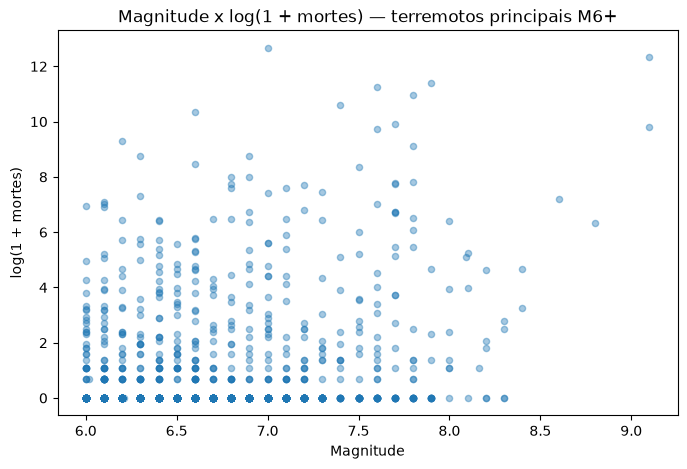

In [35]:
# Relação entre magnitude e log(1 + mortes).
ax = eventos_modelo.plot.scatter(
    x='mag',
    y='log_mortes',
    alpha=0.4,
    figsize=(8, 5)
)
ax.set_title('Magnitude x log(1 + mortes) — terremotos principais M6+')
ax.set_xlabel('Magnitude')
ax.set_ylabel('log(1 + mortes)')
plt.show()

## 14. Checagens adicionais

Os registros NOAA sem correspondência com magnitude igual ou superior a 5,5, ou com pelo menos 100 mortes, merecem revisão manual. A tabela abaixo facilita localizar esses casos.

In [36]:
noaa_para_revisar = noaa_sem_match[
    (noaa_sem_match['mag_noaa'] >= MAGNITUDE_MINIMA)
    | (noaa_sem_match['mortes_max'] >= 100)
]

print('Registros NOAA sem match que merecem revisão:', len(noaa_para_revisar))
display(noaa_para_revisar[[
    'Year', 'Mo', 'Dy', 'local', 'mag_noaa', 'mortes_max'
]].head(30))

print('\nPaíses com e sem eventos na tabela countries.csv:')
display(paises['tem_evento'].value_counts(dropna=False).rename_axis('tem_evento').to_frame('quantidade'))

Registros NOAA sem match que merecem revisão: 4


,Year,Mo,Dy,local,mag_noaa,mortes_max
403,2002.0,1.0,17.0,RWANDA: GISENYI,4.7,1001.0
416,2002.0,4.0,12.0,TAJIKISTAN; AFGHANISTAN: DO ABI-NAHRIN,5.9,50.0
1520,2019.0,9.0,24.0,PAKISTAN: MIRPUR DISTRICT,5.6,39.0
1666,2023.0,1.0,24.0,INDIA: UTTAR PRADESH; NEPAL: SUDURPASHCHIM PRO...,5.6,4.0



Países com e sem eventos na tabela countries.csv:


,quantidade
tem_evento,
False,123
True,95


## 15. Observações metodológicas

- **USGS:** o universo inicial inclui eventos de magnitude 5,5 ou superior entre 1990 e 2023.
- **País do evento:** terremotos no mar podem receber o código do país mais próximo, desde que estejam a até 250 km. Isso é uma aproximação geográfica.
- **Réplicas:** a classificação depende da janela de 30 dias e do raio associado à magnitude. É uma regra operacional adotada no projeto, não uma classificação oficial do USGS.
- **NOAA x USGS:** a correspondência é aproximada por data, distância e magnitude. Registros sem correspondência são preservados em arquivo separado para revisão.
- **Mortes ausentes:** quando o registro NOAA não informa mortes nem uma faixa, o projeto assume zero e marca `mortes_assumida_zero`. Eventos sem qualquer correspondência NOAA também recebem zero mortes, pela premissa definida no projeto.
- **Banco Mundial:** lacunas são preenchidas por interpolação entre valores conhecidos e, nas pontas da série, por preenchimento de até 12 anos. As flags `_imputado` permitem identificar os valores preenchidos.
- **Interpretação:** os indicadores finais dependem dessas decisões e devem ser apresentados como estimativas construídas a partir das fontes, não como medidas perfeitas do impacto de cada terremoto.